# 02 · Washing-machine exploratory data analysis

**Data:** official cleaned REFIT. All logic is in `src/`, and every statistic is computed from the files on disk.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from src import config as cfg
from src import visualization as viz

viz.apply_style()
pd.set_option("display.max_columns", 40, "display.width", 200, "display.max_colwidth", 70)
for folder in (cfg.FIGURES, cfg.METRICS, cfg.PREDICTIONS):
    folder.mkdir(parents=True, exist_ok=True)

from scipy import stats
from src.data_loader import eligible_houses, household_channels, read_clean_csv, wm_channel
from src import preprocessing as pp
from src.cycle_detection import detect_events, sensitivity_grid

## 1. Eligible households

Washing-machine channels come from the official README, not a hardcoded list.

In [2]:
channels = household_channels()
channels.to_csv(cfg.METRICS / "household_channels.csv", index=False)
display(channels[["house", "wm_channels_all", "wm_description", "washer_dryer_channel", "tumble_dryer_channel", "eligible", "exclusion_reason"]])
HOUSES = eligible_houses()
print("Eligible houses:", HOUSES)

,house,wm_channels_all,wm_description,washer_dryer_channel,tumble_dryer_channel,eligible,exclusion_reason
0,1,5,"Washing Machine, Beko, WMC6140",4,,False,also has a washer-dryer
1,2,2,"Washing Machine, LG, F1289TD",,,True,
2,3,6,"Washing Machine, Unknown, Unknown",,4,False,solar on aggregate
3,4,"4,5","Washing Machine(1), Servis, 6065; Washing Machine(2), Zanussi, Z917",,,False,two washing machines
4,5,3,"Washing Machine, AEG, L99695HWD",,2,True,
5,6,2,"Washing Machine, Bosch, Classixx 1200 Express",,,True,
6,7,5,"Washing Machine, Bosch, Unknown",,4,True,
7,8,4,Washing Machine,3,,False,also has a washer-dryer
8,9,3,"Washing Machine, Bosch, Classixx 6 1200 Express",2,,False,also has a washer-dryer
9,10,5,"Washing Machine, Beko, WI1382",,,True,


Eligible houses: [2, 5, 6, 7, 10, 13, 15, 16, 17, 19, 20]


**Which homes, and why.** The README lists 20 homes. **11 are used: 2, 5, 6, 7, 10, 13, 15, 16, 17, 19 and 20.** All have one washing-machine channel, and all meet the required minimum of four. No home was dropped for being inconvenient:

| Excluded | Reason |
|---|---|
| 3, 11, 21 | Solar generation affects the aggregate (Murray et al., 2017) |
| 1, 8, 9, 18 | A separate washer-dryer adds a near-identical load that the target channel does not include |
| 4 | Two washing-machine channels |
| 12 | No washing-machine channel |

**Limits of this rule.**
- Tumble-dryer homes (5, 7, 15, 17, 20) are kept. A dryer is an unlabelled heating load too, so the rule is not perfectly consistent, and those homes may be harder to model.
- **House 5's machine is labelled a washing machine, but its model (AEG L99695HWD) is sold by retailers as a heat-pump washer-dryer.** The rule could not catch this. It is kept because the label qualifies it, and notebook 03 reports results with and without it.
- House 13's README entry says its washing machine changes on 25 Mar 2015. It is kept, and that date is a point to remember when reading its results.

Notebook 03 tests the model on the four washer-dryer homes as a stress test.

## 2. Do the listed channels actually behave like washing machines?

The README warns that appliances may have been moved. Before trusting a label, we check that each channel shows the expected heater power and a plausible number of cycles.

In [3]:
data = {house: pp.prepare_clean_house(house) for house in HOUSES}
audit = pp.clean_house_audit(HOUSES)
audit.to_csv(cfg.METRICS / "clean_house_audit.csv")

rows = []
for house, frame in data.items():
    raw = read_clean_csv(house, ["Unix", "Issues"])
    step = raw["Unix"].diff().dropna()
    both = frame["aggregate"].notna() & frame["wm"].notna()
    rows.append({
        "House": house, "Aggregate channel": "Aggregate", "WM channel": audit.loc[house, "wm_channel"],
        "Start (local)": frame["local_time"].iloc[0], "End (local)": frame["local_time"].iloc[-1],
        "Calendar days": round(len(frame) / 1440, 1),
        "Median sample interval (s)": step.median(),
        "Minutes in window": len(frame),
        "Valid minutes (both signals)": int(both.sum()),
        "Missing minutes %": round(100 * (1 - both.mean()), 2),
        "Missing aggregate %": round(100 * frame["aggregate"].isna().mean(), 2),
        "Missing WM %": round(100 * frame["wm"].isna().mean(), 2),
        "Availability %": round(100 * both.mean(), 2),
        "Exact zero WM % of valid": round(100 * (frame["wm"].dropna() == 0).mean(), 2),
        "Nonzero WM % of valid": round(100 * (frame["wm"].dropna() > 0).mean(), 2),
        "Frozen aggregate (approx. h)": audit.loc[house, "hours_aggregate_frozen"],
        "Frozen WM rows": audit.loc[house, "rows_wm_frozen"],
        "Issues flag % (all rows)": round(100 * raw["Issues"].mean(), 2),
        "Issues flag % (WM on)": round(100 * frame.loc[frame["wm"] > cfg.ACTIVE_W, "issue_frac"].mean(), 2),
    })
coverage = pd.DataFrame(rows).set_index("House")
coverage.to_csv(cfg.METRICS / "household_coverage.csv")
display(coverage)

,Aggregate channel,WM channel,Start (local),End (local),Calendar days,Median sample interval (s),Minutes in window,Valid minutes (both signals),Missing minutes %,Missing aggregate %,Missing WM %,Availability %,Exact zero WM % of valid,Nonzero WM % of valid,Frozen aggregate (approx. h),Frozen WM rows,Issues flag % (all rows),Issues flag % (WM on)
House,,,,,,,,,,,,,,,,,,
2,Aggregate,Appliance2,2013-09-17 23:08:00,2015-05-28 08:05:00,617.4,7.0,889018,663666,25.35,25.34,24.57,74.65,94.40,5.60,66.9,387,0.50,3.47
5,Aggregate,Appliance3,2013-09-26 10:56:00,2015-07-06 17:48:00,648.3,7.0,933533,824378,11.69,9.60,11.55,88.31,53.53,46.47,12.4,181496,5.73,12.53
6,Aggregate,Appliance2,2013-11-28 12:15:00,2015-06-28 22:14:00,577.4,7.0,831420,699679,15.85,15.85,15.00,84.15,97.43,2.57,87.1,0,0.55,2.31
7,Aggregate,Appliance5,2013-11-01 22:01:00,2015-07-08 02:10:00,613.1,7.0,882910,766991,13.13,13.13,12.50,86.87,74.86,25.14,26.0,92,2.40,9.08
10,Aggregate,Appliance5,2013-11-20 11:31:00,2015-06-30 11:07:00,586.9,7.0,845197,685126,18.94,18.93,10.86,81.06,90.23,9.77,1208.8,270,0.45,2.63
13,Aggregate,Appliance3,2014-01-17 22:26:00,2015-05-31 11:06:00,498.5,7.0,717821,537710,25.09,25.09,22.58,74.91,84.85,15.15,302.1,501,2.61,6.25
15,Aggregate,Appliance3,2013-12-17 17:24:00,2015-07-08 02:10:00,567.3,7.0,816947,699642,14.36,14.33,13.54,85.64,96.18,3.82,55.3,2458,0.38,8.13
16,Aggregate,Appliance5,2014-01-10 10:58:00,2015-07-08 02:10:00,543.6,7.0,782773,635080,18.87,18.87,17.20,81.13,93.32,6.68,201.7,0,0.26,1.05
17,Aggregate,Appliance4,2014-03-06 16:23:00,2015-06-19 14:52:00,469.9,7.0,676650,619904,8.39,8.37,6.10,91.61,96.63,3.37,195.4,1082,1.58,13.38


**Coverage.** Dates run from September 2013 at the earliest to July 2015 at the latest, 460-648 calendar days per home. Valid minutes with both signals range from 537,710 (House 13) to 824,378 (House 5). Availability is 74.65-92.92%. Sampling is a median of 7 s in every home, not the README's 8 s.

**Zero and off are different things here.** "Exact zero" counts only valid minutes where the sensor reports 0. House 5's 46% nonzero share is mostly a 3 W standby, not activity, which is why activity uses a threshold rather than "above 0".

**House 5 needs special care.** It has 181,496 frozen washing-machine rows. Section 5a measures what that does to its energy.

**Issues flag.** The publishers flag 0.26-5.73% of rows, rising to 1.05-13.38% while the machine runs. So the flag is more common at exactly the moments that matter. Notebook 03 tests results with and without those rows.

In [ ]:
rows = []
bins = [0, 2, 5, 15, 60, 1440, np.inf]
labels = ["1-2 min", "3-5 min", "6-15 min", "16-60 min", "1-24 h", "Over 24 h"]
for house, frame in data.items():
    # A minute is missing when either signal is empty, the same definition as Availability % above.
    assert (frame.index.to_series().diff().dropna() == pd.Timedelta(minutes=1)).all()
    missing = frame["aggregate"].isna() | frame["wm"].isna()
    run = (missing != missing.shift()).cumsum()
    lengths = missing[missing].groupby(run[missing]).size()
    assert lengths.sum() == missing.sum()
    counts = pd.cut(lengths, bins=bins, labels=labels).value_counts().reindex(labels)
    rows.append({"House": house, "Gaps": len(lengths), **counts.to_dict(), "Missing minutes": int(lengths.sum()),
                 "Longest gap (days)": round(lengths.max() / 1440, 1),
                 "Share of missing minutes in gaps over 24 h %": round(100 * lengths[lengths > 1440].sum() / lengths.sum(), 1)})
gaps = pd.DataFrame(rows).set_index("House")
gaps.to_csv(cfg.METRICS / "household_gap_lengths.csv")
display(gaps)

,Gaps,1-2 min,3-5 min,6-15 min,16-60 min,1-24 h,Over 24 h,Missing minutes,Longest gap (days),Share of missing minutes in gaps over 24 h %
House,,,,,,,,,,
2,479,0,0,280,112,75,12,225352,62.0,89.8
5,934,0,0,315,349,259,11,109155,8.6,44.1
6,179,0,0,61,72,33,13,131741,33.6,91.6
7,138,0,0,68,37,21,12,115919,41.6,93.5
10,817,0,0,341,263,200,13,160071,30.8,71.9
13,743,0,0,520,150,61,12,180111,41.1,87.0
15,698,0,0,243,252,191,12,117305,8.6,63.5
16,719,0,0,236,270,196,17,147693,18.3,71.9
17,152,0,0,71,48,25,8,56746,8.6,83.8


**Missing intervals.** A gap is a run of consecutive minutes where the aggregate or the washing-machine signal is empty, the same definition as Availability % above.

- **The 11 homes have 5,211 gaps and 1,354,936 missing minutes.** Each home has 50-934 gaps, and its longest lasts 8.6-62.0 days.
- **Long gaps hold most missing time.** In 10 of 11 homes, gaps over 24 hours hold 63.5-93.5% of missing minutes. House 5 is lower at 44.1%.
- **The 1-2 and 3-5 minute columns are zero by design:** the pipeline fills gaps of 5 minutes or less and flags those minutes as imputed.

Missing minutes match the coverage table in every home. The table is saved as `outputs/metrics/household_gap_lengths.csv`.

## 3. Which clock are the timestamps on?

DOCUMENTATION GAP: the official cleaned files state that time was corrected for daylight saving. House 1 shows the correction stops when the file moves from raw Part 1 to Part 2, on 1 Oct 2014. A same-season comparison is the cleanest test, because daily routines in May-June 2014 and May-June 2015 should line up on a correct clock. If the files change clock, they will be about an hour apart.

,Clock,Houses,Best alignment shift (min),Correlation at best shift,Correlation with no shift
0,As published,11,-60,0.9653,0.8785
1,Corrected to UK local time,11,0,0.9653,0.9653


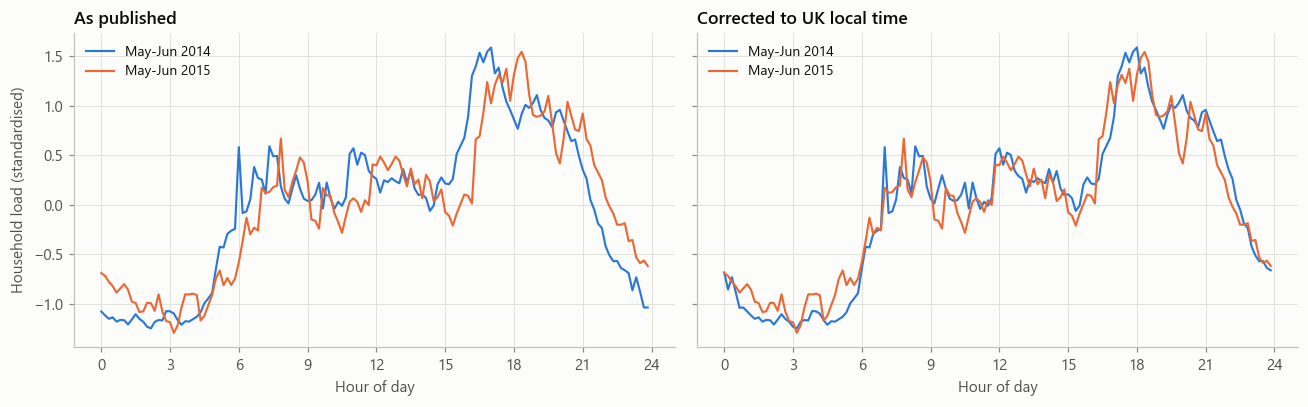

In [4]:
def aggregate_profile(clock, start, end):
    profiles = []
    for frame in data.values():
        series = frame["aggregate"].copy()
        series.index = clock(frame.index)
        chunk = series[(series.index >= start) & (series.index < end)].dropna()
        if len(chunk) > 5000:
            grouped = chunk.groupby(chunk.index.hour * 6 + chunk.index.minute // 10).mean()
            profiles.append(((grouped - grouped.mean()) / grouped.std()).to_numpy())
    return np.mean(profiles, axis=0), len(profiles)

rows, fig_data = [], {}
for label, clock in (("As published", pp.as_published_clock), ("Corrected to UK local time", pp.to_local_clock)):
    a, n_a = aggregate_profile(clock, "2014-05-01", "2014-06-25")
    b, n_b = aggregate_profile(clock, "2015-05-01", "2015-06-25")
    correlation = {lag * 10: np.corrcoef(a, np.roll(b, lag))[0, 1] for lag in range(-12, 13)}
    best = max(correlation, key=correlation.get)
    rows.append({"Clock": label, "Houses": min(n_a, n_b), "Best alignment shift (min)": best,
                 "Correlation at best shift": round(correlation[best], 4), "Correlation with no shift": round(correlation[0], 4)})
    fig_data[label] = (a, b)
clock_test = pd.DataFrame(rows)
clock_test.to_csv(cfg.METRICS / "clock_same_season_test.csv", index=False)
display(clock_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
hours = np.arange(144) / 6
for ax, (label, (a, b)) in zip(axes, fig_data.items()):
    ax.plot(hours, a, color=viz.BLUE, label="May-Jun 2014")
    ax.plot(hours, b, color=viz.ORANGE, label="May-Jun 2015")
    ax.set_title(label)
    ax.set_xlabel("Hour of day")
    ax.set_xticks(range(0, 25, 3))
    ax.legend(loc="upper left")
axes[0].set_ylabel("Household load (standardised)")
fig.tight_layout()
viz.save(fig, "02_clock_correction")
plt.show()

**A test that needs no assumption about behaviour.** On a correctly converted clock, no hour is ever duplicated or skipped. On a UK wall clock, the 01:00 hour doubles in autumn and vanishes in spring. So we count the rows printed in that hour on each clock-change day.

In [5]:
rows = []
for house in HOUSES:
    wall = pd.to_datetime(read_clean_csv(house, ["Unix"])["Unix"], unit="s")
    count = lambda start, end: int(((wall >= start) & (wall < end)).sum())
    rows.append({"House": house, "Typical rows per hour": int(wall.dt.floor("h").value_counts().median()),
                 "30 Mar 2014, 01:00 hour": count("2014-03-30 01:00", "2014-03-30 02:00"),
                 "26 Oct 2014, 01:00 hour": count("2014-10-26 01:00", "2014-10-26 02:00"),
                 "29 Mar 2015, 01:00 hour": count("2015-03-29 01:00", "2015-03-29 02:00")})
    del wall
clock_rows = pd.DataFrame(rows).set_index("House")
clock_rows.to_csv(cfg.METRICS / "clock_change_row_counts.csv")
display(clock_rows)

,Typical rows per hour,"30 Mar 2014, 01:00 hour","26 Oct 2014, 01:00 hour","29 Mar 2015, 01:00 hour"
House,,,,
2,529,600,1057,0
5,529,542,798,0
6,534,595,971,0
7,535,596,983,0
10,538,597,826,0
13,533,569,606,0
15,538,595,976,0
16,535,583,885,0
17,528,600,958,0


**The official files change clock partway through, despite saying daylight saving was corrected.** In all 11 homes, the 01:00 hour has a normal number of rows on 30 Mar 2014 (542-600), far more than normal on 26 Oct 2014 (up to 1,057), and none on 29 Mar 2015. So the early part of the file is corrected and the later part is UK wall-clock time. The row counts depend on no assumption about behaviour.

The daily-routine test agrees. As published, May-June 2014 and May-June 2015 line up best with a 60-minute shift (r 0.8785 unshifted, 0.9653 shifted). On the corrected clock no shift is needed and r is 0.9653.

**What this does and does not prove.** It shows the switch happens in every home, but the exact date, 1 Oct 2014, is established on House 1 only. All time-of-day charts below use the corrected clock. The model uses no clock features, so it is not affected.

## 4. Choosing the cycle-detection rule

**Rule:** a minute is active when power is above `ACTIVE_W`. Active runs separated by at most `EVENT_MAX_GAP_MIN` low-power minutes form one event. An event must last at least `EVENT_MIN_DURATION_MIN` and peak above `EVENT_MIN_PEAK_W`. A missing minute always ends an event.

We check each setting against the data, first the power levels and then the sensitivity of the event counts.

In [6]:
bins = [-0.1, 0, 5, 10, 20, 50, 200, 1000, 5000]
labels = ["0 W", "0-5", "5-10", "10-20", "20-50", "50-200", "200-1000", "over 1000"]
levels = pd.DataFrame({house: pd.cut(frame["wm"].dropna(), bins, labels=labels).value_counts(normalize=True).reindex(labels) * 100 for house, frame in data.items()}).T.round(2)
levels.index.name = "House"
levels.to_csv(cfg.METRICS / "wm_power_level_share.csv")
print("Share of valid minutes at each 1-minute power level (%)")
display(levels)

sensitivity = pd.concat([sensitivity_grid(frame["wm"]).assign(house=house) for house, frame in data.items()])
sensitivity.to_csv(cfg.METRICS / "event_rule_sensitivity.csv", index=False)
summary = sensitivity.groupby(["parameter", "value"]).agg(total_events=("events", "sum"), median_duration_min=("median_duration_min", "median"), median_energy_kwh=("median_energy_kwh", "median")).round(2)
display(summary)

Share of valid minutes at each 1-minute power level (%)


wm,0 W,0-5,5-10,10-20,20-50,50-200,200-1000,over 1000
House,,,,,,,,
2,94.40,0.26,0.35,0.32,1.11,2.53,0.32,0.71
5,53.53,40.22,0.33,0.67,0.86,2.55,1.15,0.70
6,97.43,0.65,0.02,0.02,0.15,1.31,0.16,0.26
7,74.86,16.63,0.06,0.09,0.51,5.71,0.67,1.48
10,90.23,0.63,0.20,0.22,0.66,5.89,1.01,1.16
13,84.85,9.73,0.06,0.15,0.89,3.06,0.40,0.87
15,96.18,0.46,0.25,0.22,0.21,1.53,0.49,0.65
16,93.32,2.84,0.04,0.10,1.18,1.35,0.34,0.83
17,96.63,0.64,0.17,0.20,0.37,1.34,0.24,0.41


total_events  median_duration_min  median_energy_kwh
parameter        value                                                      
active_w         10             4372                 78.0               0.55
                 20             4377                 74.0               0.55
                 50             4406                 73.0               0.55
max_gap_min      2              5112                 71.0               0.43
                 5              4647                 73.5               0.53
                 15             4377                 74.0               0.55
                 30             4126                 76.0               0.56
min_duration_min 5              4509                 74.0               0.55
                 10             4377                 74.0               0.55
                 20             4206                 74.5               0.55

**The rule in plain English.** The machine counts as active above 20 W. Active periods with pauses of 15 minutes or less count as one event, so events are at least 15 minutes apart. An event must last at least 10 minutes and reach 200 W at some point. Missing data always ends an event.

**Why these values.**
- **20 W:** the levels table shows very few minutes between 10 and 20 W (0.02-0.67%), so standby and real activity separate cleanly there. It also matches the washing-machine ON threshold in the seq2point paper (Zhang et al., 2018). Moving it from 10 to 50 W changes the count only from 4,372 to 4,406.
- **10 minutes:** moving between 5 and 20 minutes changes the count from 4,509 to 4,206, and median energy stays at 0.55 kWh.
- **200 W:** rejects low-level noise that never reaches a real machine stage. Isolated spikes are rejected by the 10-minute rule.
- **15-minute pause:** this setting matters most, moving the count from 5,112 (2 minutes) to 4,126 (30 minutes). Shorter pauses split cycles, and median energy falls to 0.43 kWh. Longer ones risk merging back-to-back washes. Nothing in this table picks 15 exactly, so **it is a judgement, not a measured optimum**.

These are operating events estimated from power, not verified wash cycles.

## 5. Detect events and inspect them

In [7]:
all_events = []
for house, frame in data.items():
    events = detect_events(frame["wm"])
    local = pd.Series(frame["local_time"].to_numpy(), index=frame.index)
    events["start_local"] = local.reindex(events["start"]).to_numpy()
    events["house"] = house
    all_events.append(events)
events = pd.concat(all_events, ignore_index=True)
events["hour"] = events["start_local"].dt.hour
events["weekend"] = events["start_local"].dt.dayofweek >= 5
events.to_csv(cfg.METRICS / "wm_detected_events.csv", index=False)
print(f"Detected events: {len(events):,}; incomplete (missing data within {cfg.EVENT_MAX_GAP_MIN} min of an end): {int(events['incomplete'].sum()):,}")
display(events.loc[~events["incomplete"], ["duration_min", "peak_w", "energy_kwh"]].describe(percentiles=[.05, .25, .5, .75, .95, .99]).round(2))
print("Longest events:")
display(events.nlargest(6, "duration_min")[["house", "start_local", "duration_min", "peak_w", "energy_kwh"]])

Detected events: 4,377; incomplete (missing data within 15 min of an end): 300


,duration_min,peak_w,energy_kwh
count,4077.00,4077.00,4077.00
mean,84.77,1989.19,0.55
std,43.91,402.50,0.32
min,10.00,202.50,0.01
5%,31.00,933.16,0.14
25%,58.00,2032.62,0.34
50%,74.00,2080.90,0.51
75%,111.00,2131.60,0.70
95%,146.00,2267.37,1.12
99%,243.24,2323.21,1.62


Longest events:


,house,start_local,duration_min,peak_w,energy_kwh
933,5,2015-02-27 19:17:00,572,2320.000000,3.437819
947,5,2015-03-13 18:33:00,518,2189.000000,2.636017
969,5,2015-03-28 20:50:00,470,2250.333333,2.849332
920,5,2015-02-14 21:35:00,420,2250.000000,2.775346
1005,5,2015-05-01 23:09:00,396,2241.000000,2.611562
930,5,2015-02-20 20:46:00,388,2316.000000,2.466057


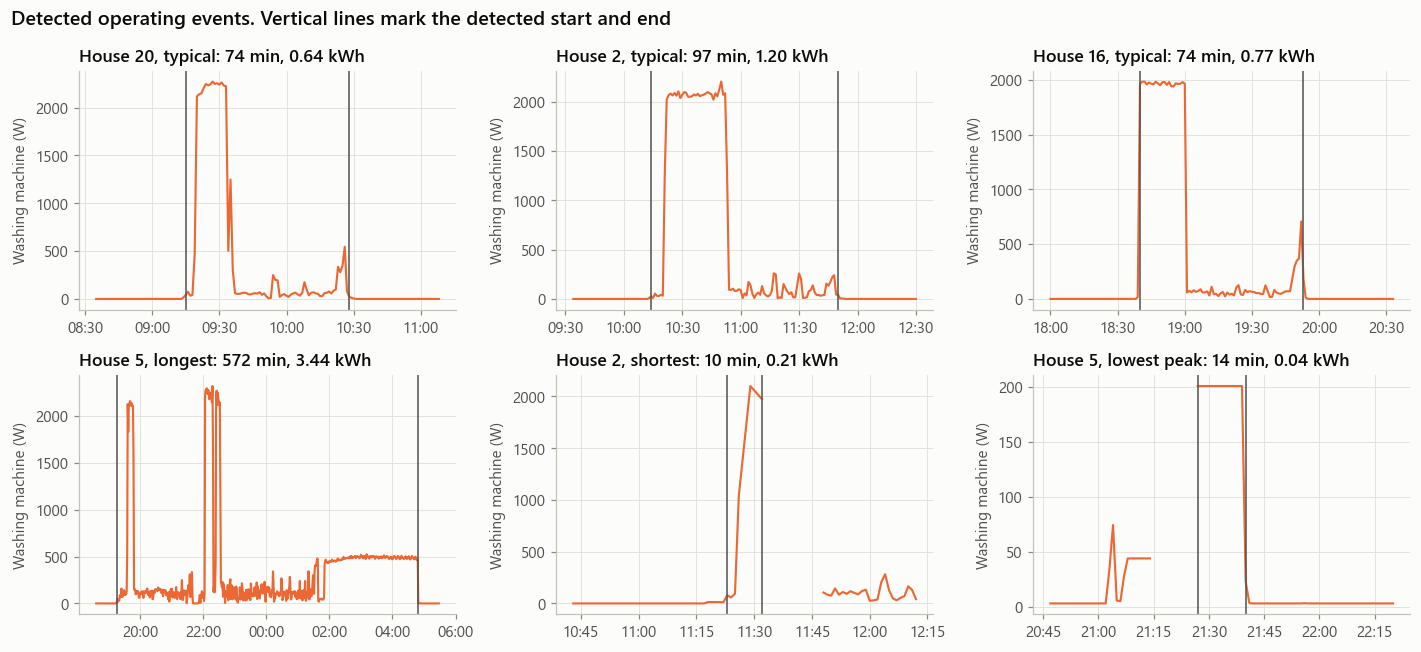

In [8]:
def plot_event(ax, house, event, pad=40, title=None):
    frame = data[house]
    window = frame[(frame.index >= event["start"] - pd.Timedelta(minutes=pad)) & (frame.index <= event["end"] + pd.Timedelta(minutes=pad))]
    ax.plot(window["local_time"], window["wm"], color=viz.ORANGE)
    ax.axvline(window["local_time"][window.index == event["start"]].iloc[0], color=viz.INK_2, linewidth=1)
    ax.axvline(window["local_time"][window.index == event["end"]].iloc[0], color=viz.INK_2, linewidth=1)
    ax.set_title(title or f"House {house}: {event['duration_min']:.0f} min, {event['energy_kwh']:.2f} kWh")
    viz.format_time_axis(ax, "%H:%M")
    ax.set_ylabel("Washing machine (W)")

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
rng = np.random.default_rng(cfg.RANDOM_SEED)
picks = []
for house in rng.choice(HOUSES, 3, replace=False):
    subset = events[events["house"] == house]
    near_median = (subset["duration_min"] - subset["duration_min"].median()).abs().idxmin()
    picks.append((int(house), events.loc[near_median], "typical"))
for house, row in events.nlargest(1, "duration_min").set_index("house").iterrows():
    picks.append((house, row, "longest"))
short = events.nsmallest(1, "duration_min").iloc[0]
picks.append((int(short["house"]), short, "shortest"))
low = events.nsmallest(1, "peak_w").iloc[0]
picks.append((int(low["house"]), low, "lowest peak"))
for ax, (house, row, tag) in zip(axes.ravel(), picks):
    plot_event(ax, house, row, title=f"House {house}, {tag}: {row['duration_min']:.0f} min, {row['energy_kwh']:.2f} kWh")
fig.suptitle("Detected operating events. Vertical lines mark the detected start and end", x=0.01, ha="left", fontweight="semibold", fontsize=13)
fig.tight_layout()
viz.save(fig, "02_B_detected_events")
plt.show()

### 5a. How much energy is sensor error?

Two checks on the official washing-machine channels. **Frozen runs** hold one value for 30 minutes or more and are masked by the pipeline. **Isolated readings** are 500 W or more, with near-zero readings on both sides, and survive the mask. Isolated readings are suspected glitches, not proven ones.

In [9]:
rows = []
for house in HOUSES:
    channel = f"Appliance{wm_channel(house)}"
    raw = read_clean_csv(house, ["Unix", channel])
    values, unix = raw[channel].to_numpy(dtype=float), raw["Unix"].to_numpy()
    del raw
    change = np.r_[0, np.flatnonzero(values[1:] != values[:-1]) + 1]
    last = np.r_[change[1:] - 1, len(values) - 1]
    level, seconds, samples = values[change], unix[last] - unix[change], last - change + 1
    before, after = np.r_[np.nan, level[:-1]], np.r_[level[1:], np.nan]
    energy = level * samples
    masked = (seconds >= cfg.STUCK_MINUTES * 60) & (level > cfg.ACTIVE_W)
    isolated = (before < 30) & (after < 30) & (level >= 500) & ~masked
    rows.append({"House": house, "Frozen runs masked": int(masked.sum()), "Frozen share of published energy %": round(100 * energy[masked].sum() / energy.sum(), 2),
                 "Isolated runs left": int(isolated.sum()), "Isolated share of remaining energy %": round(100 * energy[isolated].sum() / energy[~masked].sum(), 2)})
sensor_energy = pd.DataFrame(rows).set_index("House")
sensor_energy.to_csv(cfg.METRICS / "sensor_error_energy_share.csv")
display(sensor_energy)

,Frozen runs masked,Frozen share of published energy %,Isolated runs left,Isolated share of remaining energy %
House,,,,
2,1,0.03,31,0.06
5,123,30.70,152,2.64
6,0,0.00,109,1.88
7,1,0.08,43,0.04
10,1,0.08,75,0.73
13,2,0.43,36,0.11
15,4,0.41,55,0.75
16,0,0.00,17,0.05
17,3,0.64,316,2.43


**House 5's published energy is badly inflated.** 30.7% of its washing-machine energy in the official file comes from frozen readings, such as 2,129 W held for 13 hours. Used as published, its total would be about 44% too high. The other ten homes are at 0.64% or below. This is why the pipeline masks frozen runs.

**Isolated readings** that survive the mask are at most 2.64% of a home's energy (House 5), and under 1% in seven homes. They are suspected glitches, and some may be real. Exact 1024 W readings are one such type: they are far more common than neighbouring values, and the aggregate does not move with them. This share is small next to the model's errors, so the target was left unchanged.

### 5b. Are any detected events really frozen sensors?

Real power fluctuates from minute to minute. An event in which most active minutes hold one identical value is suspect. The frozen-sensor rule only masks runs of 30 minutes or more, so shorter ones can pass through.

In [10]:
def flat_share(house, event):
    segment = data[house]["wm"].loc[event["start"]:event["end"]].dropna().round(1)
    segment = segment[segment > cfg.ACTIVE_W]
    return segment.value_counts(normalize=True).iloc[0] if len(segment) else np.nan

events["flat_share"] = [flat_share(row.house, row) for _, row in events.iterrows()]
events["flat"] = events["flat_share"] > 0.5
flat_table = events.groupby("house").agg(events=("flat", "size"), flat_events=("flat", "sum"), flat_kwh=("energy_kwh", lambda s: s[events.loc[s.index, "flat"]].sum()), all_kwh=("energy_kwh", "sum"))
flat_table["flat_energy_pct"] = (100 * flat_table["flat_kwh"] / flat_table["all_kwh"]).round(2)
flat_table.round(2).to_csv(cfg.METRICS / "flat_events_by_house.csv")
display(flat_table.round(2))
print(f"Flat events: {int(events['flat'].sum())} of {len(events)} ({100 * events['flat'].mean():.2f}%), {100 * events.loc[events['flat'], 'energy_kwh'].sum() / events['energy_kwh'].sum():.2f}% of event energy")
events.to_csv(cfg.METRICS / "wm_detected_events.csv", index=False)

,events,flat_events,flat_kwh,all_kwh,flat_energy_pct
house,,,,,
2,327,0,0.00,201.38,0.00
5,733,48,16.58,287.18,5.77
6,129,1,0.35,82.55,0.43
7,839,0,0.00,484.44,0.00
10,606,2,0.79,403.07,0.19
13,439,1,0.04,201.71,0.02
15,256,4,0.53,199.07,0.27
16,309,0,0.00,207.17,0.00
17,289,3,0.65,107.42,0.61


Flat events: 63 of 4377 (1.44%), 0.88% of event energy


**A small problem overall, concentrated in one home.** 63 of 4,377 events (1.44%) are dominated by one held value, carrying 0.88% of event energy. Of these, 48 are in House 5, where they hold 5.77% of event energy. They remain because their share is small, but House 5's per-event statistics should be read with that in mind. A shorter frozen limit could remove them. It was not applied, because the effect is too small to justify changing the target.

### 5c. Where is the energy inside a cycle?

The traces suggest a short high-power heating stage followed by a long low-power tumbling stage. This matters for the model: the heater is large but resembles a kettle or a shower, while tumbling is distinctive but small.

In [11]:
rows = []
for house, frame in data.items():
    active = frame["wm"].dropna()
    active = active[active > cfg.ACTIVE_W]
    high = active >= 1000
    mid = (active >= 200) & (active < 1000)
    low = active < 200
    rows.append({"House": house,
                 "Active minutes at 1000+ W %": 100 * high.mean(), "Active minutes at 200-1000 W %": 100 * mid.mean(), "Active minutes under 200 W %": 100 * low.mean(),
                 "Energy at 1000+ W %": 100 * active[high].sum() / active.sum(), "Energy at 200-1000 W %": 100 * active[mid].sum() / active.sum(), "Energy under 200 W %": 100 * active[low].sum() / active.sum()})
stages = pd.DataFrame(rows).set_index("House").round(1)
stages.to_csv(cfg.METRICS / "wm_energy_by_power_band.csv")
display(stages)
print("Mean across homes:", stages.mean().round(1).to_dict())

,Active minutes at 1000+ W %,Active minutes at 200-1000 W %,Active minutes under 200 W %,Energy at 1000+ W %,Energy at 200-1000 W %,Energy under 200 W %
House,,,,,,
2,15.3,6.9,77.8,79.5,5.2,15.3
5,13.3,21.8,64.8,65.2,21.1,13.7
6,13.9,8.3,77.8,72.8,7.4,19.7
7,17.7,8.0,74.3,78.3,5.9,15.8
10,13.3,11.6,75.1,70.2,9.7,20.1
13,16.6,7.7,75.7,77.2,7.6,15.3
15,22.6,17.1,60.2,79.2,10.5,10.3
16,22.4,9.2,68.4,84.4,7.6,8.0
17,17.3,10.3,72.3,76.7,8.6,14.7


Mean across homes: {'Active minutes at 1000+ W %': 15.1, 'Active minutes at 200-1000 W %': 10.8, 'Active minutes under 200 W %': 74.0, 'Energy at 1000+ W %': 71.3, 'Energy at 200-1000 W %': 10.3, 'Energy under 200 W %': 18.4}


**This explains much of what the model can and cannot do.** Averaged across homes, **71.3% of energy arrives in the 15.1% of active minutes at 1000 W or more**, the heating stage. By contrast, 74.0% of active minutes are under 200 W, and they carry only 18.4% of energy.

So a model can get energy roughly right by finding heating, while missing most of the time the machine is running.

**House 19 is the exception.** Only 2.7% of its active minutes reach 1000 W, and 51.4% of its energy is under 200 W. Low-temperature washing is one possible reason, but that is not recorded in the data. Notebook 03 tests whether this makes the home harder to model.

**Checking the detector by eye** on the six events above:

- **Typical events (houses 20, 2, 16)** look like real cycles: a heating block of about 2 kW, then tumbling at about 100 W, with boundaries in the right places.
- **Shortest (House 2)** stops because data goes missing, not because the machine stopped. This is why incomplete events are flagged: 300 of 4,377 events (6.9%), and they are left out of per-cycle statistics.
- **Lowest peak (House 5)** is a flat 201 W for 14 minutes, a frozen sensor that is too short for the 30-minute rule (see section 5b).
- **Longest (House 5)** has two heating blocks and then a flat 500 W for about three hours, so it is not one wash. The six longest events are all in House 5, which fits a heat-pump washer-dryer, although the data cannot confirm what those stages were.

**Across complete events,** median duration is 74 minutes (5th-95th percentile 31-146), median energy is 0.51 kWh (0.14-1.12), and median peak is 2,081 W. The detector works well on typical cycles. Its errors are concentrated in one home with an unusual machine.

### 5d. How far can these events be trusted?

These checks measure where the events may not be single wash cycles.

In [12]:
from src.data_loader import parse_readme, wm_channel

pause_counts = pd.DataFrame({
    "5-minute pause": {house: len(detect_events(frame["wm"], max_gap_min=5)) for house, frame in data.items()},
    "15-minute pause (used)": {house: len(detect_events(frame["wm"], max_gap_min=15)) for house, frame in data.items()},
})
pause_counts.index.name = "House"
pause_counts.loc["Total"] = pause_counts.sum()
pause_counts.to_csv(cfg.METRICS / "event_pause_rule_counts.csv")
display(pause_counts)

by_start = events.sort_values(["house", "start"])
gap_to_previous = (by_start["start"] - by_start.groupby("house")["end"].shift()).dt.total_seconds() / 60
close_events = by_start[gap_to_previous.between(16, 60)]
event_caveats = pd.DataFrame({
    "Events": events.groupby("house").size(),
    "Over 3 hours": events[events["duration_min"] > 180].groupby("house").size(),
    "Over 5 hours": events[events["duration_min"] > 300].groupby("house").size(),
    "Starts 16-60 min after another": close_events.groupby("house").size(),
    "No minute at 1000+ W": events[events["peak_w"] < 1000].groupby("house").size(),
}).fillna(0).astype(int)
event_caveats["Starts 16-60 min after another %"] = (100 * event_caveats["Starts 16-60 min after another"] / event_caveats["Events"]).round(1)
event_caveats.to_csv(cfg.METRICS / "event_caveats_by_house.csv")
display(event_caveats)
print(f"Over 3 hours: {(events['duration_min'] > 180).sum()}; over 5 hours: {(events['duration_min'] > 300).sum()}")
print(f"Starts 16-60 min after another: {len(close_events)} ({100 * len(close_events) / len(events):.1f}%)")
print(f"No minute at 1000+ W: {(events['peak_w'] < 1000).sum()}")

print("House 13 channel label:", parse_readme()[13][wm_channel(13)])
house13 = events[events["house"] == 13]
house13_before = house13[house13["start_local"] < "2015-03-25"]
house13_after = house13[house13["start_local"] >= "2015-03-25"]
print(f"House 13 median event energy: before 25 Mar 2015 {house13_before['energy_kwh'].median():.3f} kWh ({len(house13_before)} events); from that date {house13_after['energy_kwh'].median():.3f} kWh ({len(house13_after)} events)")

,5-minute pause,15-minute pause (used)
House,,
2,344,327
5,805,733
6,139,129
7,882,839
10,636,606
13,478,439
15,267,256
16,329,309
17,301,289


,Events,Over 3 hours,Over 5 hours,Starts 16-60 min after another,No minute at 1000+ W,Starts 16-60 min after another %
house,,,,,,
2,327,19,0,33,15,10.1
5,733,35,16,176,130,24.0
6,129,6,0,14,16,10.9
7,839,16,1,71,7,8.5
10,606,14,1,55,27,9.1
13,439,2,0,111,23,25.3
15,256,1,0,30,19,11.7
16,309,3,0,21,6,6.8
17,289,1,0,25,23,8.7


Over 3 hours: 102; over 5 hours: 18
Starts 16-60 min after another: 563 (12.9%)
No minute at 1000+ W: 308
House 13 channel label: Washing Machine, Unknown, Unknown, (Changes 25 Mar 2015)
House 13 median event energy: before 25 Mar 2015 0.433 kWh (392 events); from that date 0.472 kWh (47 events)


**Events are an approximate reference, not verified cycles.**

- **Pause rule:** 4,647 events with a 5-minute pause against 4,377 with 15 minutes. Most homes move only slightly, and House 5 moves most (805 against 733).
- **Long events:** 102 last over 3 hours and 18 over 5 hours, and 16 of those 18 are in House 5.
- **Close events:** 563 events (12.9%) start 16-60 minutes after another, from 1.1% in House 19 to 25.3% in House 13. Consecutive loads and split cycles cannot be told apart.
- **Little or no heating:** 308 events have no minute at 1000+ W, and 130 of those are in House 5. They may be cold washes, or not washes at all.
- **House 13's channel** is labelled "Changes 25 Mar 2015". Median event energy shows no visible shift (0.433 kWh from 392 events before, 0.472 kWh from 47 after), but what changed is not recorded.

## 6. Household statistics

**Energy (kWh) = sum of 1-minute power readings (W) × 1 minute ÷ 60,000.** Power in W is instantaneous and energy in kWh is accumulated over time. Totals cover measured minutes only, so we also report an annualised rate to compare homes with different coverage.

In [13]:
rows = []
for house, frame in data.items():
    wm = frame["wm"].dropna()
    every_event = events[events["house"] == house]
    house_events = every_event[~every_event["incomplete"]]
    total_kwh = wm.sum() / 60_000
    valid_days = len(wm) / 1440
    rows.append({
        "House": house,
        "Start": frame["local_time"].iloc[0].date(), "End": frame["local_time"].iloc[-1].date(),
        "Valid observations (min)": len(wm),
        "Missing intervals %": round(100 * frame["wm"].isna().mean(), 2),
        "OFF % of time": round(100 * (wm <= cfg.ACTIVE_W).mean(), 2),
        "Active % of time": round(100 * (wm > cfg.ACTIVE_W).mean(), 2),
        "Events": len(every_event),
        "Incomplete events": int(every_event["incomplete"].sum()),
        "Events per week": round(len(every_event) / (valid_days / 7), 2),
        "Mean duration (min)": round(house_events["duration_min"].mean(), 1),
        "Median duration (min)": round(house_events["duration_min"].median(), 1),
        "Mean peak (W)": round(house_events["peak_w"].mean()),
        "Max 1-min power (W)": round(wm.max()),
        "Mean energy per event (kWh)": round(house_events["energy_kwh"].mean(), 3),
        "Total WM energy (kWh)": round(total_kwh, 1),
        "Annualised WM energy (kWh/yr)": round(total_kwh / valid_days * 365, 1),
        "Energy inside events %": round(100 * every_event["energy_kwh"].sum() / total_kwh, 1),
    })
house_stats = pd.DataFrame(rows).set_index("House")
house_stats.to_csv(cfg.METRICS / "household_wm_statistics.csv")
display(house_stats.T)

House,2,5,6,7,10,13,15,16,17,19,20
Start,2013-09-17,2013-09-26,2013-11-28,2013-11-01,2013-11-20,2014-01-17,2013-12-17,2014-01-10,2014-03-06,2014-03-06,2014-03-20
End,2015-05-28,2015-07-06,2015-06-28,2015-07-08,2015-06-30,2015-05-31,2015-07-08,2015-07-08,2015-06-19,2015-06-20,2015-06-23
Valid observations (min),670570,825715,706674,772540,753389,555755,706338,648123,635403,634408,623372
Missing intervals %,24.57,11.55,15.0,12.5,10.86,22.58,13.54,17.2,6.1,6.35,5.95
OFF % of time,95.32,94.74,98.12,91.63,91.28,94.79,97.11,96.3,97.64,96.14,97.58
Active % of time,4.68,5.26,1.88,8.37,8.72,5.21,2.89,3.7,2.36,3.86,2.42
Events,327,733,129,839,606,439,256,309,289,262,188
Incomplete events,33,91,10,20,33,74,12,10,6,8,3
Events per week,4.92,8.95,1.84,10.95,8.11,7.96,3.65,4.81,4.58,4.16,3.04
Mean duration (min),106.8,65.3,108.7,78.1,116.3,73.2,89.9,80.7,57.7,94.8,83.8


In [14]:
# Occupancy comes from the README household table.
occupancy = {2: 4, 5: 4, 6: 2, 7: 4, 10: 4, 13: 4, 15: 1, 16: 6, 17: 3, 19: 4, 20: 2}
context = house_stats[["Events per week", "Mean energy per event (kWh)", "Annualised WM energy (kWh/yr)"]].astype(float).assign(Occupants=pd.Series(occupancy))
display(context)
for column in ["Events per week", "Mean energy per event (kWh)", "Annualised WM energy (kWh/yr)"]:
    result = stats.spearmanr(context["Occupants"], context[column])
    print(f"Spearman, occupants vs {column}: rho = {result.statistic:.2f}, p = {result.pvalue:.3f}")
result = stats.spearmanr(context["Events per week"], context["Annualised WM energy (kWh/yr)"])
print(f"Spearman, events per week vs annual energy: rho = {result.statistic:.2f}, p = {result.pvalue:.3f}")
print("Range of annual energy, highest / lowest:", round(context["Annualised WM energy (kWh/yr)"].max() / context["Annualised WM energy (kWh/yr)"].min(), 1))

,Events per week,Mean energy per event (kWh),Annualised WM energy (kWh/yr),Occupants
House,,,,
2,4.92,0.646,158.6,4
5,8.95,0.403,198.7,4
6,1.84,0.667,62.1,2
7,10.95,0.581,330.6,4
10,8.11,0.686,283.6,4
13,7.96,0.491,193.2,4
15,3.65,0.806,150.1,1
16,4.81,0.681,169.6,6
17,4.58,0.374,90.9,3


Spearman, occupants vs Events per week: rho = 0.68, p = 0.022
Spearman, occupants vs Mean energy per event (kWh): rho = -0.08, p = 0.816
Spearman, occupants vs Annualised WM energy (kWh/yr): rho = 0.52, p = 0.103
Spearman, events per week vs annual energy: rho = 0.91, p = 0.000
Range of annual energy, highest / lowest: 6.0


**Homes differ far more than cycles do.**

- **Annual energy** varies 6.0 times, from 55.4 kWh (House 19) to 330.6 kWh (House 7).
- **Frequency** varies from 1.84 to 10.95 events per week.
- **Energy per event** varies from 0.25 to 0.81 kWh.
- **Frequency drives the total:** events per week and annual energy have a rank correlation of 0.91. More occupants go with more frequent use (rho 0.68, p = 0.022), but not with more energy per event (rho -0.08). With 11 homes and several tests, treat these as indications rather than proof.

**The detector captures nearly all the energy:** 92.0-99.7% of each home's washing-machine energy lies inside detected events, with House 5 lowest.

**How energy is calculated.** Totals count measured minutes only, and missing minutes are never treated as zero. The annualised figure assumes missing periods look like measured ones, which is not proven.

## 7. Required visualizations

### A. A representative 24 hours

Aggregate and washing-machine power share the same scale, so the machine's share of the household load is visible directly.

Valid minutes on the chosen day: 1440 of 1440


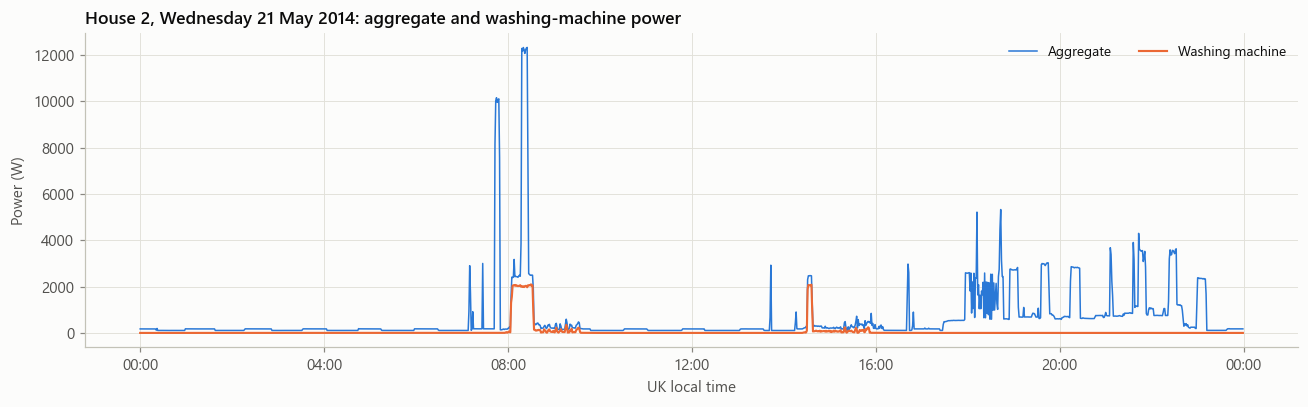

In [15]:
house = HOUSES[0]
frame = data[house].copy()
candidates = events[(events["house"] == house) & ~events["incomplete"]].copy()
candidates["day"] = candidates["start_local"].dt.normalize()
valid_per_day = frame.dropna(subset=["aggregate", "wm"]).groupby(frame.dropna(subset=["aggregate", "wm"])["local_time"].dt.normalize()).size()
full_days = valid_per_day[valid_per_day >= 1435].index
candidates = candidates[candidates["day"].isin(full_days)]
target = candidates.iloc[(candidates["duration_min"] - candidates["duration_min"].median()).abs().argsort().iloc[0]]
day = target["day"]
window = frame[(frame["local_time"] >= day) & (frame["local_time"] < day + pd.Timedelta(days=1))]
print(f"Valid minutes on the chosen day: {valid_per_day[day]} of 1440")
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(window["local_time"], window["aggregate"], color=viz.BLUE, linewidth=1, label="Aggregate")
ax.plot(window["local_time"], window["wm"], color=viz.ORANGE, label="Washing machine")
ax.set_title(f"House {house}, {day:%A %d %B %Y}: aggregate and washing-machine power")
ax.set_ylabel("Power (W)")
ax.set_xlabel("UK local time")
viz.format_time_axis(ax, "%H:%M")
ax.legend(loc="upper right", ncols=2)
fig.tight_layout()
viz.save(fig, "02_A_representative_day")
plt.show()

**What this shows.** House 2 on a day with all 1,440 minutes valid. Two washes run, starting near 08:00 and 14:30. Each shows a block of about 2 kW, followed by low-level tumbling that is hard to see in the aggregate.

**Two problems for the model are visible here.** At about 08:20 the heater runs at the same time as a much larger load, and the aggregate reaches 12 kW. In the evening, the aggregate shows repeated 2-4 kW blocks while the washing machine is off, and they look a lot like its heating stage. Notebook 03 checks which appliances cause this confusion.

### C. Cross-household comparison

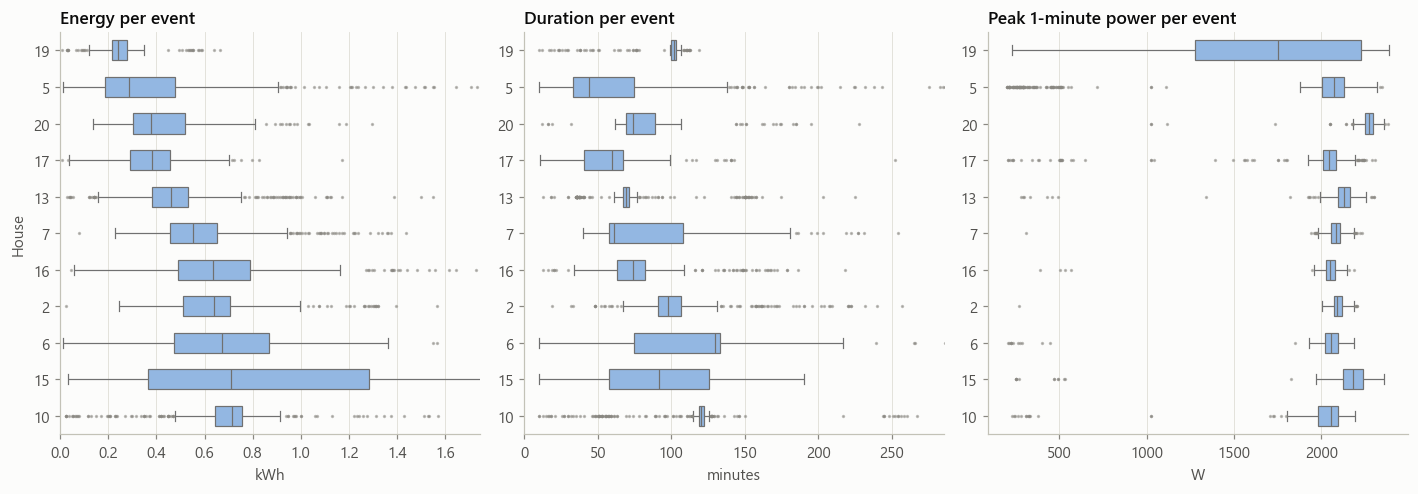

In [16]:
complete = events[~events["incomplete"]]
order = complete.groupby("house")["energy_kwh"].median().sort_values().index.astype(str).tolist()
plotted = complete.assign(house=complete["house"].astype(str))
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, (column, title, label) in zip(axes, [("energy_kwh", "Energy per event", "kWh"), ("duration_min", "Duration per event", "minutes"), ("peak_w", "Peak 1-minute power per event", "W")]):
    sns.boxplot(data=plotted, y="house", x=column, order=order, ax=ax, color="#86b6ef", width=0.55, linewidth=0.8, fliersize=1.2,
                flierprops={"markerfacecolor": viz.MUTED, "markeredgecolor": viz.MUTED, "alpha": 0.5})
    ax.set_title(title); ax.set_xlabel(label); ax.set_ylabel("House" if column == "energy_kwh" else "")
axes[0].set_xlim(0, complete["energy_kwh"].quantile(0.995))
axes[1].set_xlim(0, complete["duration_min"].quantile(0.995))
fig.tight_layout()
viz.save(fig, "02_C_household_comparison")
plt.show()

**What this shows.** Complete events only, sorted by median energy. Median energy ranges from about 0.24 kWh (House 19) to about 0.71 kWh (House 10). Some homes have tight, repeatable durations (10, 13 and 19), suggesting one favourite programme. Others are spread widely (6 and 15). Peak power is about 2 kW in nearly every home, while House 19's is much more spread out, in line with its short heating stage.

**Limit:** load size, wash temperature and programme are not recorded, so this cannot say why a home's cycles use more energy, or whether a home is less efficient.

### D. Hour-of-day distribution

All hours use the corrected UK local clock. Homes differ greatly in event counts, so each home gets equal weight: we compute each home's share of events per hour and then average.

Four-hour window with the highest mean load across these homes (local time): 17:00 to 21:00


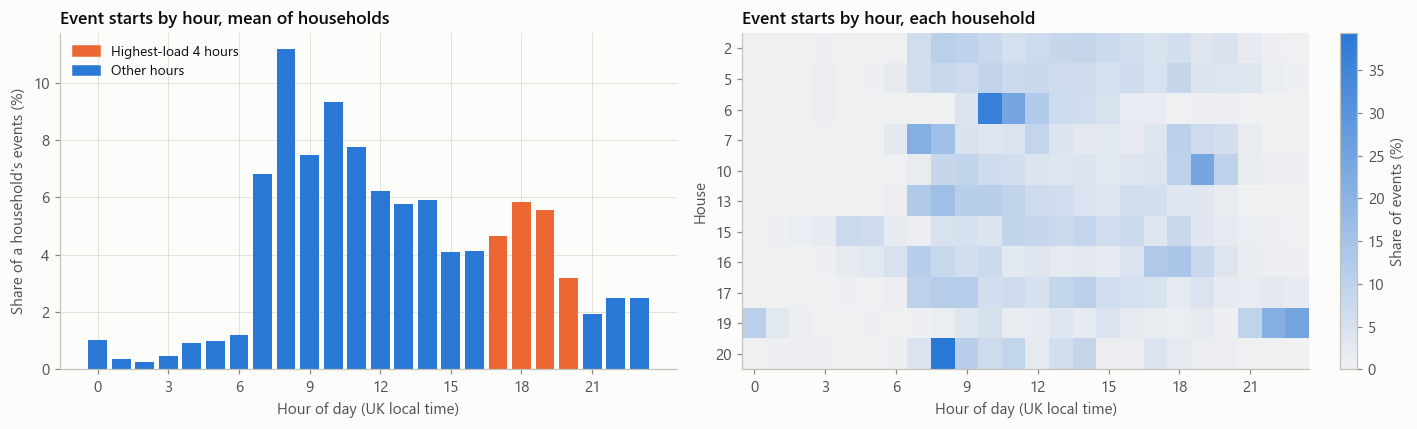

In [17]:
hour_share = (events.groupby(["house", "hour"]).size().unstack(fill_value=0).reindex(columns=range(24), fill_value=0))
hour_share = hour_share.div(hour_share.sum(axis=1), axis=0) * 100
hour_share.round(2).to_csv(cfg.METRICS / "event_start_hour_share_by_house.csv")

def load_profile():
    parts = []
    for house, frame in data.items():
        by_hour = frame["aggregate"].groupby(frame["local_time"].dt.hour).mean()
        wm_by_hour = frame["wm"].groupby(frame["local_time"].dt.hour).mean()
        parts.append(pd.DataFrame({"aggregate": by_hour, "wm": wm_by_hour, "house": house}))
    return pd.concat(parts)
profile = load_profile()
mean_aggregate = profile.groupby(level=0)["aggregate"].mean()
rolling = pd.concat([mean_aggregate, mean_aggregate.iloc[:3]]).rolling(4).mean().iloc[3:]
peak_start = int(rolling.reset_index(drop=True).idxmax())
PEAK_HOURS = [(peak_start + i) % 24 for i in range(4)]
print("Four-hour window with the highest mean load across these homes (local time):", f"{PEAK_HOURS[0]:02d}:00 to {(PEAK_HOURS[-1] + 1) % 24:02d}:00")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
mean_share = hour_share.mean()
axes[0].bar(mean_share.index, mean_share.values, color=[viz.ORANGE if h in PEAK_HOURS else viz.BLUE for h in mean_share.index], width=0.8)
axes[0].set_title("Event starts by hour, mean of households")
axes[0].set_xlabel("Hour of day (UK local time)"); axes[0].set_ylabel("Share of a household's events (%)")
axes[0].set_xticks(range(0, 24, 3))
handles = [plt.Rectangle((0, 0), 1, 1, color=viz.ORANGE), plt.Rectangle((0, 0), 1, 1, color=viz.BLUE)]
axes[0].legend(handles, ["Highest-load 4 hours", "Other hours"], loc="upper left")
image = axes[1].imshow(hour_share.values, aspect="auto", cmap=sns.light_palette(viz.BLUE, as_cmap=True), vmin=0)
axes[1].set_yticks(range(len(hour_share))); axes[1].set_yticklabels(hour_share.index)
axes[1].set_xticks(range(0, 24, 3)); axes[1].grid(False)
axes[1].set_title("Event starts by hour, each household"); axes[1].set_xlabel("Hour of day (UK local time)"); axes[1].set_ylabel("House")
fig.colorbar(image, ax=axes[1], label="Share of events (%)", fraction=0.03)
fig.tight_layout()
viz.save(fig, "02_D_hour_of_day")
plt.show()

**What this shows.** On average, starts peak in the morning, with 08:00 the busiest hour at about 11% of a home's events. **The average hides large differences.** House 6 strongly favours about 10:00, House 10 about 19:00, and House 19 about 21:00-00:00. So timing advice aimed at the average would not suit these homes.

### E. Weekday versus weekend

There are five weekdays and two weekend days, so raw counts would mislead. We compare **events per valid day**. With only 11 homes, a paired Wilcoxon signed-rank test tells us whether a difference is consistent across homes.

,Weekday events/day,Weekend events/day,Weekday median start,Weekend median start,Weekend / weekday ratio
House,,,,,
2,0.73,0.62,13.0,12.5,0.85
5,0.76,2.59,14.0,12.0,3.42
6,0.23,0.34,11.0,11.0,1.46
7,1.57,1.56,11.0,10.0,1.00
10,1.20,1.07,17.0,16.0,0.89
13,0.57,2.54,10.0,10.0,4.43
15,0.52,0.52,12.0,14.0,0.99
16,0.67,0.72,17.0,9.0,1.08
17,0.66,0.63,13.0,11.0,0.95


Homes using the machine more per day at weekends: 4 of 11
Mean rate: weekday 0.733, weekend 1.031 events/day
Wilcoxon signed-rank: statistic 32.0, p = 0.9658


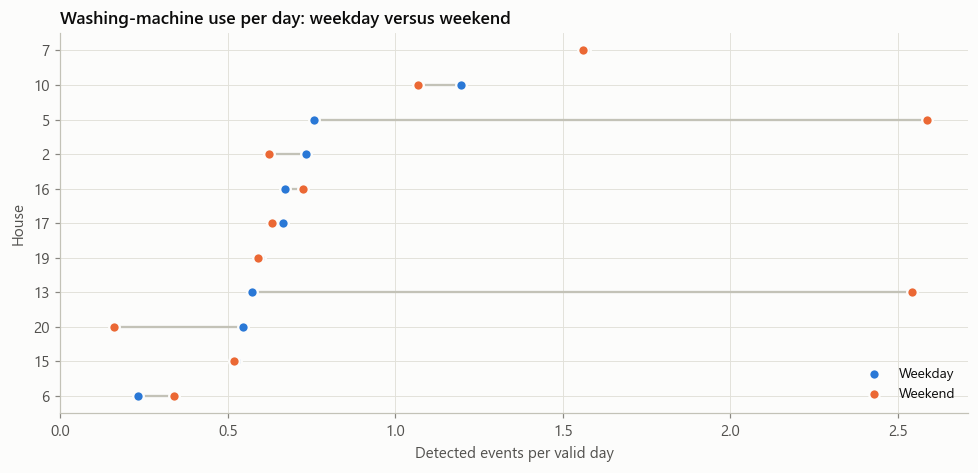

In [18]:
rows = []
for house, frame in data.items():
    valid = frame["wm"].notna()
    is_weekend = frame["local_time"].dt.dayofweek >= 5
    weekday_days = (valid & ~is_weekend).sum() / 1440
    weekend_days = (valid & is_weekend).sum() / 1440
    subset = events[events["house"] == house]
    rows.append({"House": house,
                 "Weekday events/day": (~subset["weekend"]).sum() / weekday_days,
                 "Weekend events/day": subset["weekend"].sum() / weekend_days,
                 "Weekday median start": subset.loc[~subset["weekend"], "start_local"].dt.hour.median(),
                 "Weekend median start": subset.loc[subset["weekend"], "start_local"].dt.hour.median()})
week = pd.DataFrame(rows).set_index("House")
week["Weekend / weekday ratio"] = week["Weekend events/day"] / week["Weekday events/day"]
week.round(3).to_csv(cfg.METRICS / "weekday_weekend_usage.csv")
display(week.round(2))
test = stats.wilcoxon(week["Weekend events/day"], week["Weekday events/day"])
print(f"Homes using the machine more per day at weekends: {(week['Weekend / weekday ratio'] > 1).sum()} of {len(week)}")
print(f"Mean rate: weekday {week['Weekday events/day'].mean():.3f}, weekend {week['Weekend events/day'].mean():.3f} events/day")
print(f"Wilcoxon signed-rank: statistic {test.statistic:.1f}, p = {test.pvalue:.4f}")

ranked = week.sort_values("Weekday events/day")
y = np.arange(len(ranked))
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.hlines(y, ranked["Weekday events/day"], ranked["Weekend events/day"], color=viz.AXIS, linewidth=1.5)
ax.scatter(ranked["Weekday events/day"], y, color=viz.BLUE, s=48, zorder=3, label="Weekday", edgecolors=viz.SURFACE, linewidths=1.5)
ax.scatter(ranked["Weekend events/day"], y, color=viz.ORANGE, s=48, zorder=3, label="Weekend", edgecolors=viz.SURFACE, linewidths=1.5)
ax.set_yticks(y); ax.set_yticklabels(ranked.index)
ax.set_xlabel("Detected events per valid day"); ax.set_ylabel("House")
ax.set_title("Washing-machine use per day: weekday versus weekend")
ax.set_xlim(left=0)
ax.legend(loc="lower right")
fig.tight_layout()
viz.save(fig, "02_E_weekday_weekend")
plt.show()

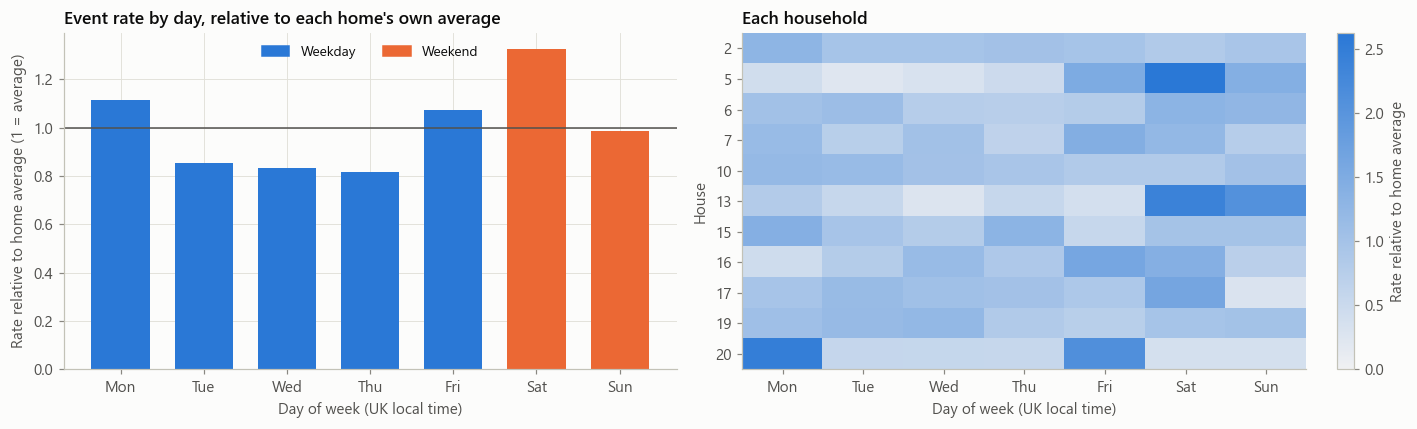

Mean relative rate: {'Mon': 1.12, 'Tue': 0.85, 'Wed': 0.83, 'Thu': 0.81, 'Fri': 1.07, 'Sat': 1.33, 'Sun': 0.98}


In [19]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
rows = {}
for house, frame in data.items():
    valid_days = frame["wm"].notna().groupby(frame["local_time"].dt.dayofweek).sum() / 1440
    subset = events[events["house"] == house]
    counts = subset["start_local"].dt.dayofweek.value_counts().reindex(range(7), fill_value=0)
    rows[house] = counts / valid_days
by_day = pd.DataFrame(rows).T.set_axis(days, axis=1)
by_day.index.name = "House"
by_day.round(3).to_csv(cfg.METRICS / "events_per_valid_day_by_weekday.csv")
relative = by_day.div(by_day.mean(axis=1), axis=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(days, relative.mean(), color=[viz.BLUE] * 5 + [viz.ORANGE] * 2, width=0.7)
axes[0].axhline(1, color=viz.INK_2, linewidth=1)
axes[0].set_title("Event rate by day, relative to each home's own average")
axes[0].set_xlabel("Day of week (UK local time)")
axes[0].set_ylabel("Rate relative to home average (1 = average)")
handles = [plt.Rectangle((0, 0), 1, 1, color=viz.BLUE), plt.Rectangle((0, 0), 1, 1, color=viz.ORANGE)]
axes[0].legend(handles, ["Weekday", "Weekend"], loc="upper center", ncols=2)
image = axes[1].imshow(relative.values, aspect="auto", cmap=sns.light_palette(viz.BLUE, as_cmap=True), vmin=0)
axes[1].set_xticks(range(7), days)
axes[1].set_yticks(range(len(relative)), relative.index)
axes[1].grid(False)
axes[1].set_title("Each household")
axes[1].set_xlabel("Day of week (UK local time)")
axes[1].set_ylabel("House")
fig.colorbar(image, ax=axes[1], label="Rate relative to home average", fraction=0.03)
fig.tight_layout()
viz.save(fig, "02_E_day_of_week")
plt.show()
print("Mean relative rate:", relative.mean().round(2).to_dict())

**What these show.** There is **no consistent weekend effect.** The average rate is higher at weekends (1.03 against 0.73 events per day), but only 4 of 11 homes use the machine more at weekends, and the paired test finds no consistent difference (p = 0.97).

The average is driven by a few homes. Houses 13 and 5 run 4.43 and 3.42 times as often per weekend day, while House 20 runs 0.29 times as often. Saturday is the highest day on average (1.33 times the home's own average), and Tuesday to Thursday are lowest (0.81-0.85), but the right-hand chart shows this pattern differs from home to home.

**Takeaway:** routines belong to households, so a general rule about laundry day would mislead.

## 8. Is there really a peak-shifting opportunity?

The brief suggests this could exist but asks us to verify it. We use the 4-hour window with the highest load in these homes, which is a limitation: it is not the actual grid or feeder peak. The window covers 16.7% of the day, so a flat usage pattern would place 16.7% of energy inside it.

**Shifting a load moves energy in time. It does not reduce the kWh a household uses.**

,WM energy in window %,"WM energy in window %, published clock",Events starting in window %,kWh per year in window,Events per week in window,"Mean kW in window, averaged over all days",WM share of household energy in window %
House,,,,,,,
2,18.69,18.30,18.65,29.65,0.92,0.02,3.03
5,18.74,18.71,21.01,37.23,1.88,0.02,2.29
6,1.38,1.26,3.10,0.86,0.06,0.00,0.09
7,26.39,26.63,26.94,87.24,2.95,0.06,5.86
10,45.10,46.28,48.18,127.88,3.91,0.09,8.03
13,10.63,8.92,13.21,20.54,1.05,0.01,1.69
15,15.68,15.08,16.41,23.54,0.60,0.02,4.65
16,40.82,39.87,37.54,69.22,1.80,0.05,5.72
17,12.20,12.40,12.46,11.09,0.57,0.01,1.25


Window: 17:00 to 21:00. Flat use would place 16.7% here.
Mean share of WM energy in window: 18.5%, median 15.7%; range 1.4-45.1%
Homes above the flat 16.7% line: 5 of 11
Wilcoxon signed-rank against 16.7%: p = 1.0000
Mean kWh/yr in window per home: 37.8; largest 127.9; total across 11 homes: 416
Mean absolute change from correcting the clock: 0.76 percentage points


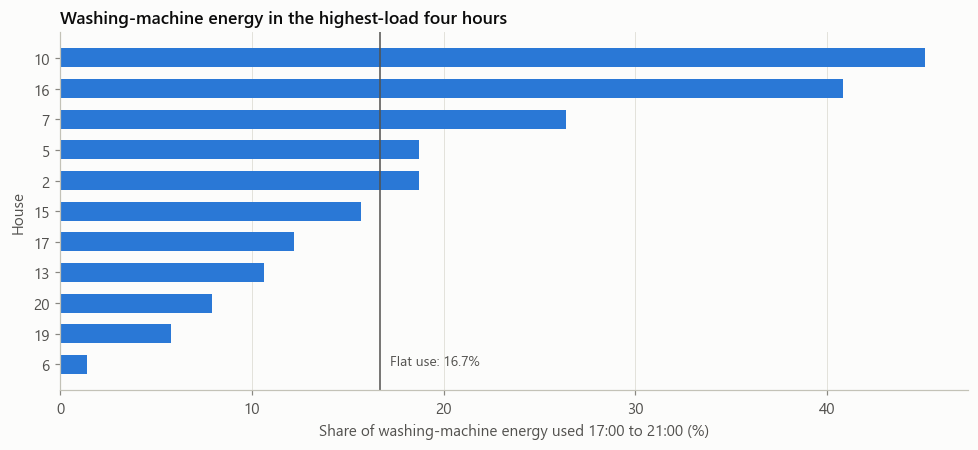

In [20]:
rows = []
for house, frame in data.items():
    valid = frame.dropna(subset=["wm"])
    energy_kwh = valid["wm"] / 60_000
    in_peak = valid["local_time"].dt.hour.isin(PEAK_HOURS)
    naive = pp.as_published_clock(valid.index)
    in_peak_naive = pd.Index(naive.hour).isin(PEAK_HOURS)
    subset = events[events["house"] == house]
    days = len(valid) / 1440
    both_measured = valid.loc[in_peak].dropna(subset=["aggregate"])  # same rows on both sides of the share
    rows.append({
        "House": house,
        "WM energy in window %": 100 * energy_kwh[in_peak].sum() / energy_kwh.sum(),
        "WM energy in window %, published clock": 100 * energy_kwh[in_peak_naive].sum() / energy_kwh.sum(),
        "Events starting in window %": 100 * subset["hour"].isin(PEAK_HOURS).mean(),
        "kWh per year in window": energy_kwh[in_peak].sum() / days * 365,
        "Events per week in window": subset["hour"].isin(PEAK_HOURS).sum() / (days / 7),
        "Mean kW in window, averaged over all days": (valid.loc[in_peak, "wm"].mean()) / 1000,
        "WM share of household energy in window %": 100 * both_measured["wm"].sum() / both_measured["aggregate"].sum(),
    })
peak = pd.DataFrame(rows).set_index("House").round(3)
peak.to_csv(cfg.METRICS / "peak_window_opportunity.csv")
display(peak.round(2))
print(f"Window: {PEAK_HOURS[0]:02d}:00 to {(PEAK_HOURS[-1] + 1) % 24:02d}:00. Flat use would place 16.7% here.")
print(f"Mean share of WM energy in window: {peak['WM energy in window %'].mean():.1f}%, median {peak['WM energy in window %'].median():.1f}%; range {peak['WM energy in window %'].min():.1f}-{peak['WM energy in window %'].max():.1f}%")
print(f"Homes above the flat 16.7% line: {(peak['WM energy in window %'] > 16.7).sum()} of {len(peak)}")
test = stats.wilcoxon(peak["WM energy in window %"] - 16.7)
print(f"Wilcoxon signed-rank against 16.7%: p = {test.pvalue:.4f}")
print(f"Mean kWh/yr in window per home: {peak['kWh per year in window'].mean():.1f}; largest {peak['kWh per year in window'].max():.1f}; total across {len(peak)} homes: {peak['kWh per year in window'].sum():.0f}")
print(f"Mean absolute change from correcting the clock: {(peak['WM energy in window %'] - peak['WM energy in window %, published clock']).abs().mean():.2f} percentage points")

ranked = peak.sort_values("WM energy in window %")
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(ranked.index.astype(str), ranked["WM energy in window %"], color=viz.BLUE, height=0.62)
ax.axvline(16.7, color=viz.INK_2, linewidth=1)
ax.text(17.2, 0.1, "Flat use: 16.7%", color=viz.INK_2, fontsize=9, va="center")
ax.set_xlabel(f"Share of washing-machine energy used {PEAK_HOURS[0]:02d}:00 to {(PEAK_HOURS[-1] + 1) % 24:02d}:00 (%)")
ax.set_ylabel("House")
ax.set_title("Washing-machine energy in the highest-load four hours")
ax.grid(axis="y", visible=False)
fig.tight_layout()
viz.save(fig, "02_peak_window_share")
plt.show()

**There is no general peak-shifting opportunity, but there may be one in a few homes.** The window is 17:00-21:00, the highest-load four hours in these homes. Flat use would place 16.7% of energy there. The average home has 18.5% (median 15.7%), only 5 of 11 are above the flat line, and the test finds no consistent difference (p = 1.00).

**The spread is what matters:** from 1.4% (House 6) to 45.1% (House 10). Three homes (10, 7, 16) hold 68% of the 416 kWh per year in this window across all 11 homes. **The absolute size is small:** about 38 kWh per home per year, and at most 128 kWh (House 10).

**Limits.**
- Shifting moves energy to another time and does not reduce kWh.
- This window is the load peak in these homes, not a measured feeder or grid peak, and it was chosen from these same homes.
- Correcting the clock changes the shares by only 0.76 percentage points on average, so this finding does not depend on the clock fix.

## Summary

1. **Homes differ more than cycles do.** Annual energy varies 6 times, and frequency is what drives it.
2. **Most energy is in a short heating stage:** 71% of energy in 15% of active minutes.
3. **There is no universal pattern** in weekend use or peak-time use. Differences between homes are the story.
4. **The data has traps:** a clock that changes partway through, a frozen sensor inflating House 5's energy by about 44%, and a machine labelled as a washing machine but sold as a washer-dryer.

**Review of this section.** Household mappings come from the README and all 11 channels show the roughly 2 kW behaviour expected of a washing machine. Incomplete events are excluded from per-cycle statistics, and rates are normalised by valid time so homes can be compared fairly. **Still weak:** the 15-minute pause is a judgement call (4,647 events at 5 minutes, 4,377 at 15), events are not verified cycles (section 5d), and with 11 homes the significance tests have limited power.